# 04 - Communities (Panama Papers)

**Question.** Do the communities of the offshore network follow the jurisdictions of the entities, the countries of their officers, or the intermediaries that created them? The hypothesis to test is that communities follow intermediaries, since one firm creates many entities in the same jurisdictions.

**Graph.** The weighted entity projection built by `src/run_stats.py` and described in notebooks 01 and 02: two entities are linked when they share a connector under the cap (officers 500, intermediaries 50, addresses 50), the weight is the number of shared connectors. 129,607 of the 213,634 entities (61 %) are isolated in the projection, so Louvain runs on the **connected part**, the 84,027 non-isolated entities. That part splits into one giant component (26,643 entities) and 10,035 small components (2 to 132 entities). Results are reported on both, and the **giant component is the main result**: a small component of two or three entities that share one officer is trivially one pure community, so the small components inflate purity without saying anything about structure.

**Method.** Louvain (Blondel et al., 2008) greedily maximizes modularity $Q = \frac{1}{2m}\sum_{ij}\left(A_{ij} - \gamma\frac{k_i k_j}{2m}\right)\delta(c_i, c_j)$, with the edge weights as $A_{ij}$ and the resolution $\gamma$ (1 is the standard modularity). The algorithm is stochastic (node order), so the `seed` is fixed and five seeds are compared. The main partition is seed 0, resolution 1.0. Implementation: NetworkX `louvain_communities`, cross-checked once against `python-louvain`.

**Comparison with the references.** Each entity gets three labels: its jurisdiction (node attribute `jur`), the most frequent country among its officers, and its intermediary. Agreement with the partition is measured by **purity** (share of entities whose community's majority label is their own label) and **normalized mutual information** (NMI, arithmetic-mean normalization, as in scikit-learn). Both are computed on the entities that have the label, and compared with a shuffled baseline (same labels, randomly permuted over the entities), because purity is high by construction when one label dominates or when communities are small.

Steps:
1. The connected part of the projection
2. Louvain: five seeds, stability, main partition
3. Resolution sweep
4. Cross-check with python-louvain
5. Community sizes
6. The three reference labels and their coverage
7. Purity and NMI against each reference
8. Inside the communities: dominant labels
9. The hub cap, the big intermediaries, and robustness across resolutions
10. Conclusions

In [1]:
from pathlib import Path
import sys, json, pickle, time, itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.load import load_panama, PROC
from src.graph import CAP

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_colwidth", 60)
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

RESOLUTION = 1.0
SEEDS = [0, 1, 2, 3, 4]
MAIN_SEED = 0
RESOLUTIONS = [0.25, 0.5, 1.0, 2.0, 4.0]
N_SHUFFLES = 5
RNG = np.random.default_rng(0)

# one color per thing, fixed everywhere in the notebook (colorblind-checked palette)
C_GIANT, C_ALL = "#2a78d6", "#eb6834"
REFS = ["jurisdiction", "officer_country", "intermediary"]
REF_LABEL = {"jurisdiction": "Jurisdiction of the entity", "officer_country": "Country of the officers", "intermediary": "Intermediary"}
REF_COLOR = {"jurisdiction": "#2a78d6", "officer_country": "#eb6834", "intermediary": "#1baf7a"}
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
GRAY = "#b0afa9"

nodes, rels = load_panama()
B, P = pickle.load(open(PROC / "graphs.pkl", "rb"))
meta = nodes.set_index("node_id")
print(f"networkx {nx.__version__}, pandas {pd.__version__}")
print(f"bipartite  {B.number_of_nodes():,} nodes, {B.number_of_edges():,} edges")
print(f"projection {P.number_of_nodes():,} nodes, {P.number_of_edges():,} edges, cap {CAP}")


def short(s, n=36):
    s = "" if pd.isna(s) else str(s)
    return s if len(s) <= n else s[: n - 1] + "…"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


def part_to_series(comms):
    # communities sorted by size, so community 0 is the largest
    comms = sorted(comms, key=len, reverse=True)
    return pd.Series({n: k for k, c in enumerate(comms) for n in c}, name="community")


def nmi(a, b):
    # normalized mutual information, arithmetic-mean normalization (scikit-learn default)
    a, b = pd.Series(a).reset_index(drop=True), pd.Series(b).reset_index(drop=True)
    a, b = pd.factorize(a)[0], pd.factorize(b)[0]
    ct = np.zeros((a.max() + 1, b.max() + 1))
    np.add.at(ct, (a, b), 1)
    pij = ct / len(a)
    pi, pj = pij.sum(1, keepdims=True), pij.sum(0, keepdims=True)
    nz = pij > 0
    mi = (pij[nz] * np.log(pij[nz] / (pi @ pj)[nz])).sum()
    h = lambda p: -(p[p > 0] * np.log(p[p > 0])).sum()
    denom = (h(pi) + h(pj)) / 2
    return float(mi / denom) if denom > 0 else 1.0


def purity(comm, lab):
    # share of entities whose label is the majority label of their community
    ct = pd.crosstab(pd.Series(comm).values, pd.Series(lab).values)
    return float(ct.max(axis=1).sum() / ct.values.sum())

networkx 3.7, pandas 3.1.1
bipartite  468,623 nodes, 511,687 edges


projection 213,634 nodes, 1,238,967 edges, cap {'officer': 500, 'intermediary': 50, 'address': 50}


## 1. The connected part of the projection

The isolated entities have no edge, so no algorithm can put them in a community with anyone. They are removed, and the report says so. What is left is the connected part: all components with at least two entities. The giant component is kept apart because it is the only place where the question is open.

In [2]:
isolated = [n for n, d in P.degree() if d == 0]
C = P.copy()
C.remove_nodes_from(isolated)                      # connected part: all non-isolated entities
comps = sorted(nx.connected_components(C), key=len, reverse=True)
# Giant component, built in the node order of the projection. Louvain's result depends on the node order even with a fixed
# seed, and a subgraph taken from a set would follow Python's per-process hash order, so the seed would not reproduce the run.
giant_nodes = comps[0]
G = nx.Graph()
G.add_nodes_from((n, d) for n, d in C.nodes(data=True) if n in giant_nodes)
G.add_edges_from((u, v, d) for u, v, d in C.edges(data=True) if u in giant_nodes)
csize = np.array([len(c) for c in comps])

rows = []
for name, H in (("projection", P), ("connected part (non-isolated)", C), ("giant component", G)):
    rows.append({"graph": name, "entities": H.number_of_nodes(), "share_of_entities": H.number_of_nodes() / P.number_of_nodes(),
                 "edges": H.number_of_edges(), "components": nx.number_connected_components(H),
                 "total_weight": int(H.size(weight="weight"))})
display(pd.DataFrame(rows).set_index("graph").style.format({"share_of_entities": "{:.1%}", "entities": "{:,}", "edges": "{:,}", "components": "{:,}", "total_weight": "{:,}"}))

bins = pd.cut(csize, [1, 2, 5, 20, 132, 10**6], labels=["2", "3-5", "6-20", "21-132", "giant"])
cls = pd.DataFrame({"components": pd.Series(bins).value_counts().sort_index(),
                    "entities": pd.Series(csize).groupby(bins, observed=False).sum()})
cls["share_of_connected_part"] = cls.entities / csize.sum()
print("Components of the connected part by size:")
display(cls.style.format({"share_of_connected_part": "{:.1%}"}))
print(f"{len(isolated):,} isolated entities ({len(isolated) / P.number_of_nodes():.1%}) are excluded from everything below.")

,entities,share_of_entities,edges,components,total_weight
graph,,,,,
projection,"213,634",100.0%,"1,238,967","139,643","1,453,432"
connected part (non-isolated),"84,027",39.3%,"1,238,967","10,036","1,453,432"
giant component,"26,643",12.5%,"831,726",1,"1,017,846"


Components of the connected part by size:


,components,entities,share_of_connected_part
2,4669,9338,11.1%
3-5,2973,10898,13.0%
6-20,1847,18413,21.9%
21-132,546,18735,22.3%
giant,1,26643,31.7%


129,607 isolated entities (60.7%) are excluded from everything below.


## 2. Louvain: five seeds, stability, main partition

Louvain is run with the edge weights, resolution 1.0, and seeds 0 to 4, on the giant component and on the whole connected part. For each run: number of communities, modularity, size of the largest community, share of entities in the ten largest. Stability is the NMI between the partitions of two seeds: 1 means identical partitions. The main partition for the rest of the notebook is seed 0.

In [3]:
def run_louvain(H, seed, resolution=RESOLUTION):
    t = time.time()
    comms = nx.community.louvain_communities(H, weight="weight", resolution=resolution, seed=seed)
    q = nx.community.modularity(H, comms, weight="weight")
    return part_to_series(comms), q, time.time() - t

runs, rows = {}, []
for name, H in (("giant", G), ("connected part", C)):
    for s in SEEDS:
        part, q, dt = run_louvain(H, s)
        runs[(name, s)] = part
        sz = part.value_counts()
        rows.append({"graph": name, "seed": s, "communities": len(sz), "modularity": q, "largest": int(sz.iloc[0]),
                     "share_top10": sz.iloc[:10].sum() / len(part), "seconds": dt})
seed_table = pd.DataFrame(rows)
display(seed_table.style.format({"modularity": "{:.4f}", "share_top10": "{:.1%}", "seconds": "{:.0f}"}).hide(axis="index"))

print("Across the five seeds:")
for name in ("giant", "connected part"):
    t = seed_table[seed_table.graph == name]
    pair_nmi = [nmi(runs[(name, a)], runs[(name, b)].reindex(runs[(name, a)].index)) for a, b in itertools.combinations(SEEDS, 2)]
    print(f"  {name:15s} communities {t.communities.min()}-{t.communities.max()}, modularity {t.modularity.min():.4f}-{t.modularity.max():.4f}, "
          f"pairwise NMI between seeds mean {np.mean(pair_nmi):.3f} (min {np.min(pair_nmi):.3f})")

part_G = runs[("giant", MAIN_SEED)]
part_C = runs[("connected part", MAIN_SEED)]
Q_G = seed_table.query("graph == 'giant' and seed == @MAIN_SEED").modularity.iloc[0]
Q_C = seed_table.query("graph == 'connected part' and seed == @MAIN_SEED").modularity.iloc[0]
# the partition of the connected part, restricted to the giant component, against the partition computed on the giant component alone
restricted = part_C.reindex(part_G.index)
print(f"\nMain partition (seed {MAIN_SEED}, resolution {RESOLUTION}): giant component {part_G.nunique()} communities, Q = {Q_G:.4f}; "
      f"connected part {part_C.nunique()} communities, Q = {Q_C:.4f}.")
print(f"Communities of the connected part restricted to the giant component: {restricted.nunique()} communities, NMI with the giant-only run = {nmi(part_G, restricted):.3f}.")

graph,seed,communities,modularity,largest,share_top10,seconds
giant,0,158,0.9575,875,24.4%,12
giant,1,159,0.9574,979,25.5%,11
giant,2,159,0.9574,883,24.4%,11
giant,3,159,0.9574,852,23.9%,12
giant,4,160,0.9573,885,24.4%,12
connected part,0,10167,0.9771,914,8.4%,23
connected part,1,10165,0.9771,914,8.3%,21
connected part,2,10169,0.9771,1036,8.7%,22
connected part,3,10167,0.9770,990,8.9%,21
connected part,4,10168,0.9771,991,8.9%,23


Across the five seeds:
  giant           communities 158-160, modularity 0.9573-0.9575, pairwise NMI between seeds mean 0.984 (min 0.976)


  connected part  communities 10165-10169, modularity 0.9770-0.9771, pairwise NMI between seeds mean 0.997 (min 0.996)

Main partition (seed 0, resolution 1.0): giant component 158 communities, Q = 0.9575; connected part 10167 communities, Q = 0.9771.
Communities of the connected part restricted to the giant component: 131 communities, NMI with the giant-only run = 0.967.


## 3. Resolution sweep

The resolution $\gamma$ sets the scale: below 1 Louvain merges into fewer, larger communities; above 1 it splits. One seed (0), on the giant component. The NMI column compares each partition with the main one (resolution 1.0). The partitions are kept to test, in section 9, whether the comparison with the references depends on the resolution.

,communities,modularity_at_gamma_1,largest,median_size,share_top10,nmi_vs_main,seconds
resolution,,,,,,,
0.25,88,0.9518,2997,164,42.0%,0.899,12
0.50,114,0.9564,1181,140,31.2%,0.950,12
1.00,158,0.9575,875,92,24.4%,1.000,12
2.00,213,0.9571,767,66,19.0%,0.956,12
4.00,274,0.9551,452,56,14.4%,0.927,12


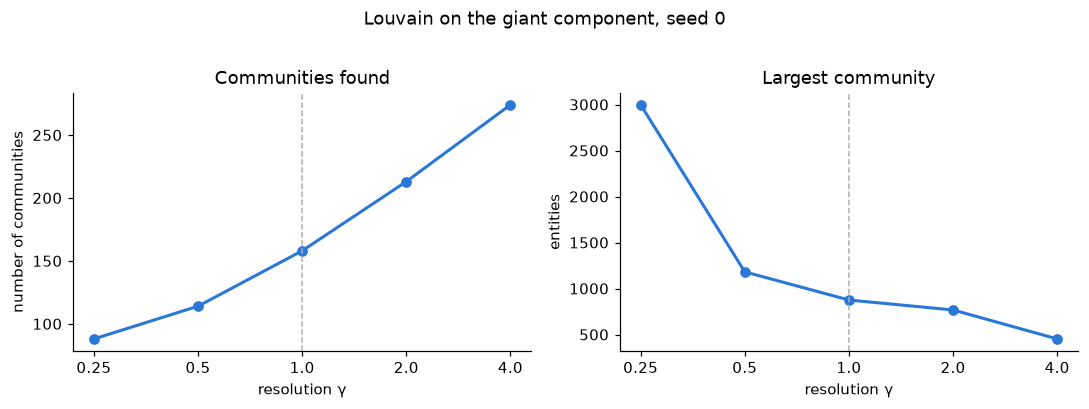

In [4]:
sweep_parts, rows = {}, []
for r in RESOLUTIONS:
    part, q, dt = run_louvain(G, MAIN_SEED, resolution=r)
    sweep_parts[r] = part
    sz = part.value_counts()
    rows.append({"resolution": r, "communities": len(sz), "modularity_at_gamma_1": nx.community.modularity(G, [set(part.index[part == k]) for k in sz.index], weight="weight"),
                 "largest": int(sz.iloc[0]), "median_size": float(sz.median()), "share_top10": sz.iloc[:10].sum() / len(part),
                 "nmi_vs_main": nmi(part, part_G.reindex(part.index)), "seconds": dt})
sweep = pd.DataFrame(rows).set_index("resolution")
display(sweep.style.format({"modularity_at_gamma_1": "{:.4f}", "share_top10": "{:.1%}", "nmi_vs_main": "{:.3f}", "seconds": "{:.0f}", "median_size": "{:.0f}"}).format_index("{:.2f}"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(sweep.index, sweep.communities, "o-", color=C_GIANT, lw=2, ms=6)
axes[0].set_xscale("log"); axes[0].set_xticks(RESOLUTIONS); axes[0].set_xticklabels(RESOLUTIONS)
axes[0].set_xlabel("resolution γ"); axes[0].set_ylabel("number of communities"); axes[0].set_title("Communities found")
axes[1].plot(sweep.index, sweep.largest, "o-", color=C_GIANT, lw=2, ms=6)
axes[1].set_xscale("log"); axes[1].set_xticks(RESOLUTIONS); axes[1].set_xticklabels(RESOLUTIONS)
axes[1].set_xlabel("resolution γ"); axes[1].set_ylabel("entities"); axes[1].set_title("Largest community")
for ax in axes:
    ax.axvline(RESOLUTION, color=GRAY, lw=1, ls="--")
    ax.minorticks_off()
fig.suptitle("Louvain on the giant component, seed 0", y=1.02)
savefig("04_resolution_sweep.png")

## 4. Cross-check with python-louvain

Same graph (giant component), same resolution, one run. The two implementations differ in node order and tie-breaking, so the partitions are not expected to be identical, only to have the same modularity and a high NMI.

In [5]:
import community as community_louvain  # python-louvain
t = time.time()
pl = pd.Series(community_louvain.best_partition(G, weight="weight", resolution=RESOLUTION, random_state=MAIN_SEED))
q_pl = community_louvain.modularity(pl.to_dict(), G, weight="weight")
print(f"python-louvain: {pl.nunique()} communities, Q = {q_pl:.4f} ({time.time() - t:.0f}s); NetworkX: {part_G.nunique()} communities, Q = {Q_G:.4f}; "
      f"NMI between the two partitions = {nmi(part_G, pl.reindex(part_G.index)):.3f}.")

python-louvain: 158 communities, Q = 0.9574 (19s); NetworkX: 158 communities, Q = 0.9575; NMI between the two partitions = 0.990.


## 5. Community sizes

Rank-size plot (log-log) of the main partition on the giant component and on the connected part, and the cumulative share of the giant component's entities covered by its largest communities.

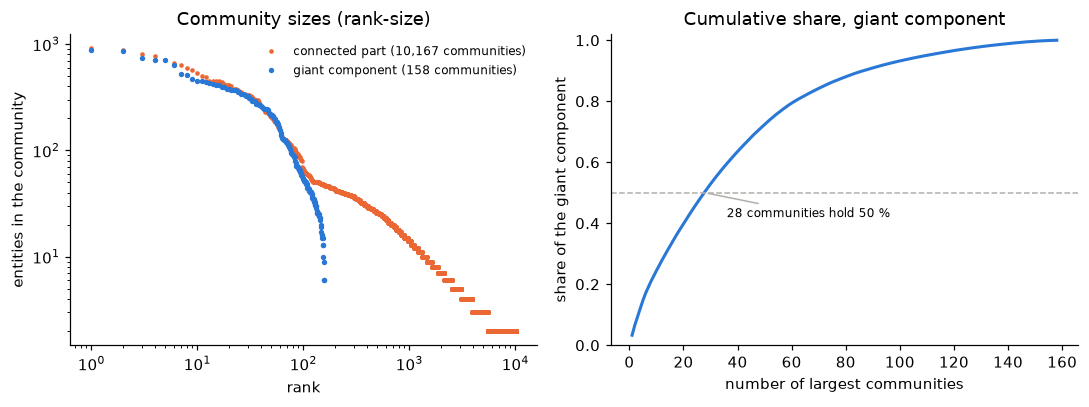

Giant component: 158 communities, largest 875, median 92, smallest 6; 75 communities with at least 100 entities hold 86.3% of it; 28 communities hold half of it.
Connected part: 10,167 communities, of which 7,643 have 5 entities or fewer (24.1% of the connected part).


Communities of the connected part that are exactly one small component: 10,034 of 10,035 small components.


In [6]:
szG, szC = part_G.value_counts().values, part_C.value_counts().values
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].loglog(np.arange(1, len(szC) + 1), szC, ".", ms=4, color=C_ALL, label=f"connected part ({len(szC):,} communities)")
axes[0].loglog(np.arange(1, len(szG) + 1), szG, ".", ms=5, color=C_GIANT, label=f"giant component ({len(szG)} communities)")
axes[0].set_xlabel("rank"); axes[0].set_ylabel("entities in the community"); axes[0].set_title("Community sizes (rank-size)")
axes[0].legend(frameon=False, fontsize=8)
cum = np.cumsum(szG) / szG.sum()
axes[1].plot(np.arange(1, len(szG) + 1), cum, color=C_GIANT, lw=2)
axes[1].set_xlabel("number of largest communities"); axes[1].set_ylabel("share of the giant component")
axes[1].set_title("Cumulative share, giant component"); axes[1].set_ylim(0, 1.02)
k50 = int(np.searchsorted(cum, 0.5) + 1)
axes[1].axhline(0.5, color=GRAY, lw=1, ls="--"); axes[1].annotate(f"{k50} communities hold 50 %", (k50, 0.5), (k50 + 8, 0.42), fontsize=8, arrowprops={"arrowstyle": "-", "color": GRAY})
savefig("04_community_sizes.png")

print(f"Giant component: {len(szG)} communities, largest {szG[0]:,}, median {np.median(szG):.0f}, smallest {szG[-1]}; "
      f"{(szG >= 100).sum()} communities with at least 100 entities hold {szG[szG >= 100].sum() / szG.sum():.1%} of it; {k50} communities hold half of it.")
print(f"Connected part: {len(szC):,} communities, of which {(szC <= 5).sum():,} have 5 entities or fewer ({szC[szC <= 5].sum() / szC.sum():.1%} of the connected part).")
print(f"Communities of the connected part that are exactly one small component: {sum(1 for c in comps[1:] if part_C.reindex(list(c)).nunique() == 1):,} of {len(comps) - 1:,} small components.")

## 6. The three reference labels and their coverage

- **Jurisdiction**: the `jur` attribute of the entity (where the company is registered).
- **Officer country**: every `officer_of` link of the entity (all officers, capped or not, since labels describe the entity, not the graph), the `countries` field of each officer, the most frequent country among them. An officer without a country is ignored. If two countries tie, the first in alphabetical order is kept and the tie is counted below.
- **Intermediary**: the `intermediary_of` link of the entity. Every entity has exactly one (checked below), so the label is the intermediary's node id, and its name is used for display.

A metric is computed on the entities that have the label. Missing labels are not a class.

In [7]:
ent = pd.DataFrame(index=pd.Index(list(C.nodes), name="node_id"))
ent["name"] = meta.name.reindex(ent.index)
ent["in_giant"] = ent.index.isin(G.nodes)
ent["community_giant"] = part_G.reindex(ent.index)
ent["community_all"] = part_C.reindex(ent.index)

# jurisdiction
ent["jurisdiction"] = meta.jurisdiction_description.reindex(ent.index)

# intermediary (one per entity)
im = rels[rels.rel_type == "intermediary_of"]
per_entity = im.groupby("node_id_end").node_id_start.nunique()
print(f"Intermediaries per entity: min {per_entity.min()}, max {per_entity.max()} (entities with more than one: {(per_entity > 1).sum()}).")
ent["intermediary"] = im.drop_duplicates("node_id_end").set_index("node_id_end").node_id_start.reindex(ent.index)
inter_name = meta.name
inter_degree = im.groupby("node_id_start").node_id_end.nunique()        # entities per intermediary (bipartite degree)
ent["intermediary_capped"] = ent.intermediary.map(inter_degree) > CAP["intermediary"]

# officer country: mode over the entity's officers that have a country
of = rels[rels.rel_type == "officer_of"][["node_id_start", "node_id_end"]].rename(columns={"node_id_start": "officer", "node_id_end": "node_id"})
of = of[of.node_id.isin(ent.index)]
of["country"] = of.officer.map(meta.countries)
n_off = of.groupby("node_id").size()
of = of.dropna(subset=["country"])
of = of.assign(country=of.country.str.split(";")).explode("country")
cnt = of.groupby(["node_id", "country"]).size().rename("n").reset_index()
cnt = cnt.sort_values(["node_id", "n", "country"], ascending=[True, False, True])
first = cnt.groupby("node_id").nth(0).set_index("node_id")
second = cnt.groupby("node_id").nth(1).set_index("node_id")
ties = (first.n == second.n.reindex(first.index)).sum()
ent["officer_country"] = first.country.reindex(ent.index)
print(f"Entities of the connected part with at least one officer: {ent.index.isin(n_off.index).sum():,}; with at least one officer whose country is known: {len(first):,}; "
      f"ties between two countries: {ties:,} ({ties / len(first):.1%}, first in alphabetical order kept).")

rows = []
for scope, mask in (("giant component", ent.in_giant), ("connected part", pd.Series(True, index=ent.index))):
    for ref in REFS:
        lab = ent.loc[mask, ref]
        vc = lab.value_counts()
        rows.append({"scope": scope, "reference": REF_LABEL[ref], "entities_with_label": int(lab.notna().sum()), "coverage": lab.notna().mean(),
                     "distinct_labels": int(lab.nunique()), "largest_label": inter_name.get(vc.index[0], vc.index[0]) if ref == "intermediary" else vc.index[0],
                     "share_of_largest_label": vc.iloc[0] / lab.notna().sum()})
coverage = pd.DataFrame(rows)
display(coverage.style.format({"coverage": "{:.1%}", "share_of_largest_label": "{:.1%}", "entities_with_label": "{:,}", "distinct_labels": "{:,}"}).hide(axis="index"))

Intermediaries per entity: min 1, max 1 (entities with more than one: 0).


Entities of the connected part with at least one officer: 61,916; with at least one officer whose country is known: 49,861; ties between two countries: 8,070 (16.2%, first in alphabetical order kept).


scope,reference,entities_with_label,coverage,distinct_labels,largest_label,share_of_largest_label
giant component,Jurisdiction of the entity,"26,643",100.0%,16,British Virgin Islands,70.9%
giant component,Country of the officers,"21,936",82.3%,148,Jersey,18.5%
giant component,Intermediary,"26,643",100.0%,"1,205",CONSULCO INTERNATIONAL LIMITED,6.8%
connected part,Jurisdiction of the entity,"84,027",100.0%,20,British Virgin Islands,57.9%
connected part,Country of the officers,"49,861",59.3%,179,British Virgin Islands,13.4%
connected part,Intermediary,"84,027",100.0%,"7,065",CONSULCO INTERNATIONAL LIMITED,2.3%


## 7. Purity and NMI against each reference

**Purity** of the partition with respect to a label: in each community take the majority label, count the entities that carry it, divide by the number of labeled entities. It is 1 when every community is homogeneous, but it is also high when there are many small communities, or when one label covers most entities (the British Virgin Islands hold half of them). **Inverse purity** does the same from the label's side: the share of entities that sit in the community where most of their label lives. It is 1 when each label is inside one community. **NMI** is symmetric and penalizes both kinds of error; 1 means the partition and the label carry the same information, 0 means independence.

The shuffled baseline keeps the label distribution and destroys any link with the graph, by permuting the labels over the entities (mean over 5 permutations). A reference explains the communities when its scores sit well above its own baseline. Sanity checks first: NMI of the partition with itself, and a shuffled partition.

Sanity: NMI(partition, itself) = 1.0000; NMI(partition, shuffled partition) = 0.0789; purity(partition, itself) = 1.0000.


scope,reference,entities,purity,purity_shuffled,inverse_purity,inverse_purity_shuffled,nmi,nmi_shuffled
giant component,Jurisdiction of the entity,"26,643",0.744,0.709,0.073,0.034,0.130,0.010
giant component,Country of the officers,"21,936",0.570,0.189,0.206,0.042,0.425,0.055
giant component,Intermediary,"26,643",0.506,0.070,0.787,0.090,0.774,0.199
connected part,Jurisdiction of the entity,"84,027",0.808,0.602,0.024,0.011,0.183,0.063
connected part,Country of the officers,"49,861",0.696,0.247,0.104,0.020,0.483,0.218
connected part,Intermediary,"84,027",0.813,0.135,0.767,0.097,0.904,0.567


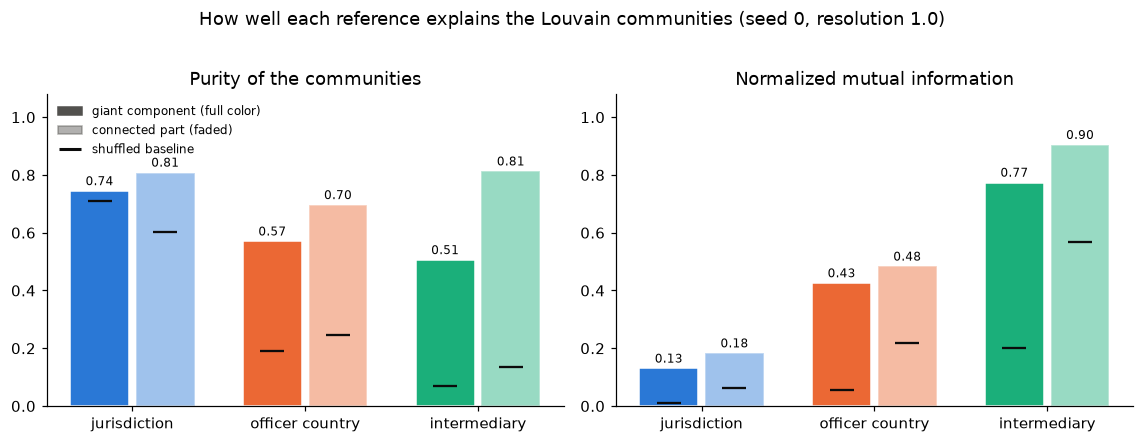

In [8]:
def scores(comm, lab, rng, n_shuffles=N_SHUFFLES):
    m = lab.notna()
    c, l = comm[m], lab[m]
    base = []
    for _ in range(n_shuffles):
        ls = pd.Series(rng.permutation(l.values), index=l.index)
        base.append((purity(c, ls), purity(ls, c), nmi(c, ls)))
    base = np.mean(base, axis=0)
    return {"entities": int(m.sum()), "purity": purity(c, l), "purity_shuffled": base[0],
            "inverse_purity": purity(l, c), "inverse_purity_shuffled": base[1], "nmi": nmi(c, l), "nmi_shuffled": base[2]}

g = ent[ent.in_giant]
print(f"Sanity: NMI(partition, itself) = {nmi(g.community_giant, g.community_giant):.4f}; "
      f"NMI(partition, shuffled partition) = {nmi(g.community_giant, RNG.permutation(g.community_giant.values)):.4f}; "
      f"purity(partition, itself) = {purity(g.community_giant, g.community_giant):.4f}.")

rows = []
for scope, sub, col in (("giant component", g, "community_giant"), ("connected part", ent, "community_all")):
    for ref in REFS:
        rows.append({"scope": scope, "reference": REF_LABEL[ref], **scores(sub[col], sub[ref], RNG)})
res = pd.DataFrame(rows)
fmt = {c: "{:.3f}" for c in res.columns if c not in ("scope", "reference", "entities")}
fmt["entities"] = "{:,}"
display(res.style.format(fmt).hide(axis="index"))

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=False)
w = 0.38
for ax, metric, title in ((axes[0], "purity", "Purity of the communities"), (axes[1], "nmi", "Normalized mutual information")):
    for j, scope in enumerate(("giant component", "connected part")):
        t = res[res.scope == scope].set_index("reference").loc[[REF_LABEL[r] for r in REFS]]
        x = np.arange(len(REFS)) + (j - 0.5) * w
        ax.bar(x, t[metric], width=w - 0.04, color=[REF_COLOR[r] for r in REFS], alpha=1.0 if j == 0 else 0.45, edgecolor="white", linewidth=1)
        ax.scatter(x, t[f"{metric}_shuffled"], marker="_", s=260, color="#0b0b0b", zorder=3)
        for xi, v in zip(x, t[metric]):
            ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(np.arange(len(REFS))); ax.set_xticklabels(["jurisdiction", "officer country", "intermediary"])
    ax.set_ylim(0, 1.08); ax.set_title(title)
handles = [Patch(color="#52514e", label="giant component (full color)"), Patch(color="#52514e", alpha=0.45, label="connected part (faded)"),
           Line2D([], [], color="#0b0b0b", marker="_", ms=14, mew=2, ls="", label="shuffled baseline")]
axes[0].legend(handles=handles, frameon=False, fontsize=8, loc="upper left")
fig.suptitle("How well each reference explains the Louvain communities (seed 0, resolution 1.0)", y=1.02)
savefig("04_reference_scores.png")

## 8. Inside the communities: dominant labels

For each community of the giant component: its size, its dominant jurisdiction, dominant officer country and dominant intermediary, with the share of the community each one covers. The table shows the twelve largest communities. The figure shows, for every community, the share of the dominant label, as a cumulative distribution weighted by community size: a curve close to the right edge means the reference is homogeneous inside most communities.

,entities,jurisdiction,jurisdiction_share,officer_country,officer_country_share,intermediary,intermediary_share
community,,,,,,,
0,875,British Virgin Islands,71%,Jersey,45%,NWT MANAGEMENT S.A.,23%
1,867,British Virgin Islands,53%,Panama,43%,HORIZON INVESTMENT SA,9%
2,742,British Virgin Islands,36%,Jersey,19%,"MOSSACK FONSECA & CO. CZ, S.R.O",11%
3,715,British Virgin Islands,59%,Panama,48%,HORIZON INVESTMENT SA,10%
4,707,British Virgin Islands,87%,Jersey,44%,ROYAL BANK OF CANADA TRUST COMPAN…,21%
5,639,British Virgin Islands,48%,Bahamas,39%,CONSULCO INTERNATIONAL LIMITED,78%
6,523,British Virgin Islands,89%,Jersey,81%,NAUTILUS TRUST COMPANY LIMITED,38%
7,518,British Virgin Islands,85%,Gibraltar,52%,STM FIDECS MANAGEMENT LTD.,38%
8,471,British Virgin Islands,86%,Jersey,57%,SALAMANCA GROUP TRUST JERSEY LTD,33%


Share of the dominant label, over the communities of the giant component (weighted by entities):
  Jurisdiction of the entity   weighted mean 0.74; entities in communities where it covers ≥ 80 %: 44.3%
  Country of the officers      weighted mean 0.56; entities in communities where it covers ≥ 80 %: 19.8%
  Intermediary                 weighted mean 0.51; entities in communities where it covers ≥ 80 %: 21.0%


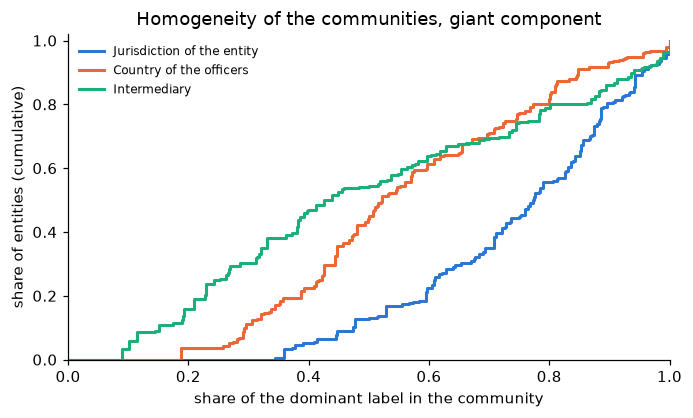

In [9]:
def dominant(sub, ref):
    vc = sub[ref].dropna().value_counts()
    if vc.empty:
        return pd.Series({f"{ref}": None, f"{ref}_share": np.nan})
    lab = vc.index[0]
    return pd.Series({f"{ref}": inter_name.get(lab, lab) if ref == "intermediary" else lab, f"{ref}_share": vc.iloc[0] / vc.sum()})

comm = g.groupby("community_giant").apply(lambda s: pd.concat([pd.Series({"entities": len(s)})] + [dominant(s, r) for r in REFS]), include_groups=False)
comm["entities"] = comm.entities.astype(int)
comm.index = comm.index.astype(int)
comm.index.name = "community"
cols = ["entities", "jurisdiction", "jurisdiction_share", "officer_country", "officer_country_share", "intermediary", "intermediary_share"]
show = comm[cols].head(12).copy()
show["intermediary"] = show.intermediary.map(lambda s: short(s, 34))
display(show.style.format({c: "{:.0%}" for c in cols if c.endswith("_share")}))

print("Share of the dominant label, over the communities of the giant component (weighted by entities):")
for ref in REFS:
    s, wgt = comm[f"{ref}_share"], comm.entities
    ok = s.notna()
    print(f"  {REF_LABEL[ref]:28s} weighted mean {np.average(s[ok], weights=wgt[ok]):.2f}; entities in communities where it covers ≥ 80 %: {wgt[ok & (s >= .8)].sum() / wgt.sum():.1%}")

fig, ax = plt.subplots(figsize=(6.4, 3.9))
for ref in REFS:
    s, wgt = comm[f"{ref}_share"], comm.entities
    ok = s.notna()
    order = np.argsort(s[ok].values)
    x = s[ok].values[order]; y = np.cumsum(wgt[ok].values[order]) / wgt.sum()
    ax.step(np.r_[0, x], np.r_[0, y], where="post", lw=2, color=REF_COLOR[ref], label=REF_LABEL[ref])
ax.set_xlabel("share of the dominant label in the community"); ax.set_ylabel("share of entities (cumulative)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Homogeneity of the communities, giant component")
savefig("04_dominant_share.png")

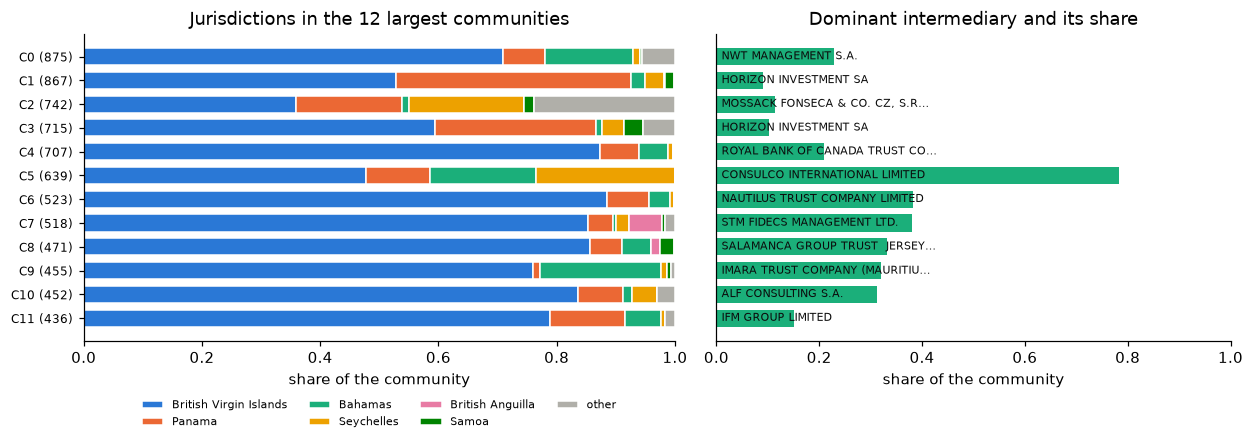

In [10]:
# composition of the twelve largest communities
top12 = comm.head(12).index
topj = g.jurisdiction.value_counts().index[:6]
ct = pd.crosstab(g.community_giant, g.jurisdiction.where(g.jurisdiction.isin(topj), "other")).loc[top12]
ct = ct[[j for j in list(topj) + ["other"] if j in ct.columns]]
share = ct.div(ct.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
left = np.zeros(len(top12))
for k, col in enumerate(share.columns):
    axes[0].barh(np.arange(len(top12)), share[col], left=left, color=GRAY if col == "other" else CAT[k], label=col, height=0.72, edgecolor="white", linewidth=1)
    left += share[col].values
axes[0].set_yticks(np.arange(len(top12))); axes[0].set_yticklabels([f"C{c} ({n:,})" for c, n in zip(top12, comm.loc[top12, 'entities'])], fontsize=8)
axes[0].invert_yaxis(); axes[0].set_xlim(0, 1); axes[0].set_xlabel("share of the community")
axes[0].set_title("Jurisdictions in the 12 largest communities")
axes[0].legend(frameon=False, fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.16))

axes[1].barh(np.arange(len(top12)), comm.loc[top12, "intermediary_share"], color=REF_COLOR["intermediary"], height=0.72)
for i, c in enumerate(top12):
    axes[1].text(0.01, i, short(comm.loc[c, "intermediary"], 30), va="center", fontsize=7, color="#0b0b0b")
axes[1].set_yticks([]); axes[1].invert_yaxis(); axes[1].set_xlim(0, 1); axes[1].set_xlabel("share of the community")
axes[1].set_title("Dominant intermediary and its share")
savefig("04_community_composition.png")

## 9. The hub cap, the big intermediaries, and robustness across resolutions

**Caveat.** The projection ignores intermediaries with more than 50 entities when it links entities. The entities of Mossack Fonseca or Orion House are therefore never linked *because* they share that intermediary: when they end up in the same community, it is through shared officers or addresses. The intermediary label is still assigned to every entity, so the comparison is fair, but it is biased against the hypothesis for exactly the entities of the biggest firms. The cells below measure how many entities of the giant component are in that case, how purity differs between them and the others, and over how many communities the biggest intermediaries are spread. Then the comparison of section 7 is repeated on the partitions of the resolution sweep.

In [11]:
capped = g.intermediary_capped
print(f"Entities of the giant component whose intermediary is above the cap ({CAP['intermediary']} entities): {capped.sum():,} of {len(g):,} ({capped.mean():.1%}), "
      f"served by {g.intermediary[capped].nunique()} intermediaries. The other {(~capped).sum():,} entities are served by {g.intermediary[~capped].nunique():,} intermediaries.")
for name, m in (("capped intermediary", capped), ("uncapped intermediary", ~capped)):
    sub = g[m]
    print(f"  {name:22s} purity {purity(sub.community_giant, sub.intermediary):.3f}, inverse purity {purity(sub.intermediary, sub.community_giant):.3f}, NMI {nmi(sub.community_giant, sub.intermediary):.3f}")

spread = g.groupby("intermediary").agg(entities=("community_giant", "size"), communities=("community_giant", "nunique"),
                                        main_community_share=("community_giant", lambda s: s.value_counts().iloc[0] / len(s)))
spread["name"] = spread.index.map(lambda i: short(inter_name.get(i, i), 40))
spread["entities_total"] = spread.index.map(inter_degree)
spread["capped"] = spread.entities_total > CAP["intermediary"]
print("\nThe ten intermediaries with the most entities in the giant component:")
display(spread.sort_values("entities", ascending=False).head(10)[["name", "entities_total", "capped", "entities", "communities", "main_community_share"]]
        .style.format({"main_community_share": "{:.0%}", "entities_total": "{:,}", "entities": "{:,}"}).hide(axis="index"))

rows = []
for r, part in sweep_parts.items():
    row = {"resolution": r, "communities": part.nunique()}
    for ref in REFS:
        sc = scores(part.reindex(g.index), g[ref], RNG, n_shuffles=2)
        row[f"purity_{ref}"] = sc["purity"]; row[f"nmi_{ref}"] = sc["nmi"]
    rows.append(row)
robust = pd.DataFrame(rows).set_index("resolution")
print("\nPurity and NMI of the three references on the giant component, by resolution (seed 0):")
display(robust.style.format({c: "{:.3f}" for c in robust.columns if c != "communities"}).format_index("{:.2f}"))

Entities of the giant component whose intermediary is above the cap (50 entities): 17,278 of 26,643 (64.9%), served by 326 intermediaries. The other 9,365 entities are served by 879 intermediaries.
  capped intermediary    purity 0.703, inverse purity 0.678, NMI 0.795
  uncapped intermediary  purity 0.377, inverse purity 0.988, NMI 0.817



The ten intermediaries with the most entities in the giant component:


name,entities_total,capped,entities,communities,main_community_share
CONSULCO INTERNATIONAL LIMITED,"3,168",True,"1,802",10,28%
MOSSACK FONSECA & CO.,"4,364",True,"1,075",9,34%
BOS TRUST COMPANY (JERSEY) LIMITED,689,True,531,9,62%
MOSSACK FONSECA & CO. (SINGAPORE) PTE L…,"3,888",True,529,28,45%
CHESTERFIELD GROUP LIMITED,"1,140",True,476,5,63%
CANNON ASSET MANAGEMENT LTD.,607,True,423,3,86%
NWT MANAGEMENT S.A.,555,True,400,8,50%
MINERVA TRUST & CORPORATE SERVICES LIMI…,768,True,347,9,42%
CREDIT SUISSE CHANNEL ISLANDS LIMIT…,918,True,340,9,70%
ALF CONSULTING S.A.,496,True,326,12,43%



Purity and NMI of the three references on the giant component, by resolution (seed 0):


,communities,purity_jurisdiction,nmi_jurisdiction,purity_officer_country,nmi_officer_country,purity_intermediary,nmi_intermediary
resolution,,,,,,,
0.25,88,0.729,0.116,0.518,0.396,0.416,0.723
0.50,114,0.737,0.121,0.554,0.415,0.472,0.756
1.00,158,0.744,0.130,0.570,0.425,0.506,0.774
2.00,213,0.754,0.140,0.604,0.445,0.555,0.797
4.00,274,0.759,0.143,0.631,0.458,0.605,0.816


## 10. Conclusions

**Setting.** Louvain on the connected part of the weighted entity projection: 84,027 entities (39 % of the 213,634), the 129,607 isolated entities being excluded. Resolution 1.0, seed 0, node order fixed so that the seed reproduces the run. The five seeds give 158 to 160 communities on the giant component, the same modularity (0.957) and a pairwise NMI of 0.98, so the partition is stable. python-louvain finds 158 communities, modularity 0.957 and NMI 0.99 with the NetworkX result.

**Shape.** The giant component (26,643 entities) splits into 158 communities, the largest with 875 entities, median 92; 28 communities hold half of it, 75 communities of at least 100 entities hold 86 %. A modularity of 0.957 is very high: the giant component is a set of dense blocks joined by few edges, which fits the diameter of 30 measured in notebook 02. On the whole connected part, 10,034 of the 10,035 small components come out as exactly one community each, so the 10,167 communities are mostly components in disguise.

**Which reference explains the communities.** On the giant component, NMI ranks the references clearly: intermediary 0.77, officer country 0.43, jurisdiction 0.13 (shuffled baselines 0.20, 0.06 and 0.01). Purity reads the other way (jurisdiction 0.74, officer country 0.57, intermediary 0.51), but the jurisdiction purity is only 0.04 above its shuffled baseline of 0.71: the British Virgin Islands hold 71 % of the component, so a random partition is "pure" too. Inverse purity settles it: 79 % of entities sit in the community where most of their intermediary's clients sit, against 21 % for the officer country and 7 % for the jurisdiction. Communities are not jurisdictions. They are the client books of intermediaries and, to a lesser extent, groups of officers from the same country.

**Hypothesis confirmed, with a nuance.** The order intermediary > officer country > jurisdiction holds at every resolution from 0.25 to 4. But a community is usually larger than one intermediary: the dominant intermediary covers 51 % of its community on average, and the largest communities group several firms from the same place (Jersey trust companies, Panama law firms), which is why officer country comes second. Raising the resolution keeps splitting communities along intermediary lines (intermediary purity rises from 0.42 to 0.61) without making them follow jurisdictions (0.73 to 0.76).

**Hub cap.** 65 % of the giant component's entities (17,278) have an intermediary above the cap of 50, so their intermediary created no edge. They still cluster by intermediary (NMI 0.80, purity 0.70), through the nominee officers and addresses that a big firm's clients share. The entities of the small intermediaries each sit inside one community (inverse purity 0.99), but a community groups several of them (purity 0.38). The cap removes the mechanical effect of a shared intermediary; the result survives it.

**Why the giant component is the result to report.** On the whole connected part the intermediary scores look better (purity 0.81, NMI 0.90), but the shuffled NMI baseline is already 0.57 there: thousands of components of 2 to 5 entities are pure by construction. The connected-part numbers are kept for completeness; the giant component is the honest test.

**To state in the report:** Louvain (NetworkX, weighted, resolution 1.0, seed 0, 5 seeds checked), isolated entities excluded, giant component as the main result, purity read against its shuffled baseline, NMI as the headline metric, the cap caveat.

In [12]:
summary = {
    "resolution": RESOLUTION, "seeds": SEEDS, "main_seed": MAIN_SEED, "n_shuffles": N_SHUFFLES,
    "isolated_entities": len(isolated), "connected_part_entities": C.number_of_nodes(), "giant_entities": G.number_of_nodes(),
    "giant_communities": int(part_G.nunique()), "giant_modularity": float(Q_G),
    "connected_communities": int(part_C.nunique()), "connected_modularity": float(Q_C),
    "python_louvain_modularity": float(q_pl), "python_louvain_nmi_vs_networkx": nmi(part_G, pl.reindex(part_G.index)),
    "seed_table": seed_table.to_dict(orient="records"), "resolution_sweep": sweep.reset_index().to_dict(orient="records"),
    "coverage": coverage.to_dict(orient="records"), "scores": res.to_dict(orient="records"),
    "robustness_by_resolution": robust.reset_index().to_dict(orient="records"),
    "top_communities": comm.head(12).reset_index().to_dict(orient="records"),
}
def convert(o):
    if isinstance(o, dict): return {str(k): convert(v) for k, v in o.items()}
    if isinstance(o, list): return [convert(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
json.dump(convert(summary), open(PROC / "04_communities_summary.json", "w"), indent=2)
ent[["in_giant", "community_giant", "community_all", "jurisdiction", "officer_country", "intermediary", "intermediary_capped"]].to_csv(PROC / "04_partition.csv")
print("Wrote", PROC / "04_communities_summary.json", "and", PROC / "04_partition.csv")

Wrote C:\Master\Graph Analytics\offshore-graph\data\processed\04_communities_summary.json and C:\Master\Graph Analytics\offshore-graph\data\processed\04_partition.csv
